# CODE 5.1: Compare PatchCore and YOLO on the Test Photos

> **Goal:** answer the main question of this project. On the same test photos, which model catches more defects: PatchCore, which never saw a labeled defect photo, or YOLO, trained with 5, 10, 20 or 40 labeled defect photos?
>
> - **Input:** the scores of notebooks 4.1 and 4.3: `results/patchcore/split_1_scores.csv` and `results/yolo/split_1_scores.csv` (and the same for splits 2 and 3)
> - **Output:**
>   - `results/evaluation/score_limits.csv`: the PASS/REJECT limit of every model, set on the validation photos
>   - `results/evaluation/test_decisions.csv`: PASS or REJECT for every test photo and every model
>   - `results/evaluation/test_results.csv`: the catch rate, false-reject rate and AUROC of every model on the test photos of every split
>
> **This is the first time the test photos are looked at.** All rules below were written down before (README > How the models are judged), and they are not changed after seeing the results. Otherwise the test photos would decide the rules, and that would be data leakage.

### How the Test Works

> Like in a factory, every model has to say **PASS** or **REJECT** for each photo. A score alone is not a decision, so every model needs a **limit**: a photo with a score above the limit gets REJECT.
>
> The two models give scores on different scales (PatchCore's distances are around 2, YOLO's confidences are between 0 and 1), so every model gets its own limit, found with the same rule:
>
> 1. Take the 50 normal validation photos of the split, with their scores from this model.
> 2. A factory does not want to throw away good gum, so at most 5% of these good photos may get REJECT. 5% of 50 is 2.5, so at most 2 photos.
> 3. Sort the 50 scores from high to low. The limit is the 3rd-highest score: the 2 photos above it get REJECT, the other 48 get PASS.
>
> Then the limit is used once on the 150 test photos of the same split:
>
> - **Catch rate:** the share of the 50 defect test photos that get REJECT. Higher is better.
> - **False-reject rate:** the share of the 100 normal test photos that get REJECT. The limit allows at most 5% on the validation photos; on new photos it can end up a bit higher or lower.
> - **AUROC:** as in notebook 4.3, now on the test photos: 50 x 100 = 5,000 pairs of a defect photo and a normal photo. It does not need a limit.
>
> This is done for every model of every split: PatchCore once per split, YOLO once per split and per k. The 3 splits share some test photos (two splits share 48 to 51 of their 150, notebook 1.3), but each split gives its own limits and its own results.

### Words Used in This Notebook

> - **Limit:** the score above which a photo gets REJECT. Every model has its own limit for every split.
> - **Catch rate:** the share of defect photos that get REJECT, in percent. Other projects often call it recall.
> - **Miss:** a defect photo that gets PASS.
> - **False reject:** a good photo that gets REJECT by mistake. **False-reject rate:** their share, in percent.
> - **Clearly catches more:** one model catches more defect photos than the other in all 3 splits (Step 3).
> - **AUROC:** the chance that a random defect photo gets a higher score than a random normal photo. 1.0 means always, 0.5 means guessing (see README).

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths.
> - `numpy`, `pandas`: work with numbers and tables.
> - `matplotlib`: draws the figures.
> - `roc_auc_score` (scikit-learn): computes the AUROC.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `PATCHCORE_DIR`: the PatchCore scores (notebook 4.1).
> - `YOLO_DIR`: the YOLO scores (notebook 4.3).
> - `EVALUATION_DIR`: where the limits and test results are saved. These files are small, and the next notebooks and the demo read them.
>
> If notebook 4.1 or 4.3 has not been run, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PATCHCORE_DIR = os.path.join(ROOT_DIR, "results", "patchcore")
YOLO_DIR = os.path.join(ROOT_DIR, "results", "yolo")
EVALUATION_DIR = os.path.join(ROOT_DIR, "results", "evaluation")

if not os.path.exists(os.path.join(PATCHCORE_DIR, "split_3_scores.csv")):
    raise FileNotFoundError("results/patchcore/split_3_scores.csv not found. Run notebook 4.1 first.")
if not os.path.exists(os.path.join(YOLO_DIR, "split_3_scores.csv")):
    raise FileNotFoundError("results/yolo/split_3_scores.csv not found. Run notebook 4.3 first.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `SPLITS`, `K_VALUES`: the 3 splits, and the amounts of labeled defect photos YOLO was trained with.
> - `MAX_FALSE_REJECT`: 0.05, so at most 5% of the normal validation photos may get REJECT.
> - `MODELS`: the names of the 5 models of every split, in the order of the tables.
> - `DEFECT_TYPES`: the 5 defect types, from the most to the least common (README).
> - `EXAMPLE_SPLIT`: Step 2 draws the test scores of split 1.

In [3]:
SPLITS = [1, 2, 3]
K_VALUES = [5, 10, 20, 40]
MAX_FALSE_REJECT = 0.05
MODELS = ["PatchCore"] + [f"YOLO k = {k}" for k in K_VALUES]
DEFECT_TYPES = ["chunk of gum missing", "corner missing", "small cracks", "similar colour spot", "scratches"]
EXAMPLE_SPLIT = 1

## Functions

### The Limit

> `score_limit()` finds the limit from the scores of the normal validation photos:
>
> - `allowed`: how many normal photos may get REJECT. 5% of 50 is 2.5, and `np.floor` rounds it down to 2.
> - `np.sort(...)[::-1]` sorts the scores from high to low. Counting from 0, position `allowed` is the 3rd-highest score: that is the limit. The 2 scores above it get REJECT.

In [4]:
def score_limit(normal_scores, max_false_reject):
    allowed = int(np.floor(max_false_reject * len(normal_scores)))
    return np.sort(normal_scores)[::-1][allowed]

### Count the Results

> `summarize()` takes the test photos of one model, each with its decision (`rejected`: True for REJECT), and counts:
>
> - the defect photos, how many of them were caught, and the catch rate in percent,
> - the normal photos, how many of them got REJECT by mistake, and the false-reject rate in percent,
> - the AUROC of the scores (without the limit).

In [5]:
def summarize(photos):
    defect = photos[photos["is_defect"]]
    normal = photos[~photos["is_defect"]]
    return {"defect photos": len(defect), "caught": int(defect["rejected"].sum()),
            "catch rate (%)": 100 * defect["rejected"].mean(),
            "normal photos": len(normal), "false rejects": int(normal["rejected"].sum()),
            "false-reject rate (%)": 100 * normal["rejected"].mean(),
            "AUROC": roc_auc_score(photos["is_defect"], photos["score"])}

### Who Clearly Catches More

> `verdict()` gets, for one k, the difference in caught defect photos (YOLO minus PatchCore) in each of the 3 splits:
>
> - all 3 above 0: YOLO clearly catches more,
> - all 3 below 0: PatchCore clearly catches more,
> - anything else: no clear winner, because the answer depends on the split.

In [6]:
def verdict(differences):
    if (differences > 0).all():
        return "YOLO clearly catches more"
    if (differences < 0).all():
        return "PatchCore clearly catches more"
    return "no clear winner"

### Draw a Result Against k

> `plot_against_k()` draws one result (for example the catch rate) against k:
>
> - **YOLO:** the mean of the 3 splits as a line with dots, and a light band from the lowest to the highest split.
> - **PatchCore:** it does not use labeled defect photos, so k does not change it: a flat dashed line (mean of the 3 splits) with its own band.

In [7]:
def plot_against_k(ax, results, column):
    yolo = results[results["model"] != "PatchCore"].groupby("k")[column]
    patchcore = results.loc[results["model"] == "PatchCore", column]
    ax.plot(K_VALUES, yolo.mean().loc[K_VALUES], marker="o", color="tab:blue", label="YOLO, mean of 3 splits")
    ax.fill_between(K_VALUES, yolo.min().loc[K_VALUES], yolo.max().loc[K_VALUES], color="tab:blue", alpha=0.2,
                    label="YOLO, lowest to highest split")
    ax.axhline(patchcore.mean(), color="tab:orange", linestyle="--", label="PatchCore, mean of 3 splits")
    ax.axhspan(patchcore.min(), patchcore.max(), color="tab:orange", alpha=0.2, label="PatchCore, lowest to highest split")
    ax.set_xscale("log", base=2)
    ax.set_xticks(K_VALUES, [str(k) for k in K_VALUES])
    ax.set_xlabel("labeled defect photos for YOLO (k)")
    ax.set_title(column)

## Load Data

### Load the Scores of Both Models

> `scores` is one table with every validation and test photo, for every split and every model:
>
> - `split`, `model` (`PatchCore`, or `YOLO k = 5` and so on), `k` (0 for PatchCore: no labeled defect photos),
> - `image`, `crop_image`, `part` (`val` or `test`), `is_defect`, `defect_types`, `score`.
>
> Below: a check that both models scored exactly the same photos in every split, and a table with the number of photos of every model in every part. Every row should show 50 normal and 10 defect validation photos, and 100 normal and 50 defect test photos.

In [8]:
tables = []
for s in SPLITS:
    patchcore = pd.read_csv(os.path.join(PATCHCORE_DIR, f"split_{s}_scores.csv"))
    patchcore["model"], patchcore["k"] = "PatchCore", 0
    yolo = pd.read_csv(os.path.join(YOLO_DIR, f"split_{s}_scores.csv"))
    yolo["model"] = "YOLO k = " + yolo["k"].astype(str)
    for table in [patchcore, yolo]:
        table["split"] = s
        tables.append(table[["split", "model", "k", "image", "crop_image", "part", "is_defect", "defect_types", "score"]])
scores = pd.concat(tables, ignore_index=True).fillna({"defect_types": ""})

same_photos = all(set(scores.loc[(scores["split"] == s) & (scores["model"] == model), "image"])
                  == set(scores.loc[(scores["split"] == s) & (scores["model"] == "PatchCore"), "image"])
                  for s in SPLITS for model in MODELS)
print(f"Rows: {len(scores)}")
print("Both models scored the same photos in every split:", same_photos)

photo_group = (scores["part"] + " " + scores["is_defect"].map({False: "normal", True: "defect"})).rename("photos")
counts = scores.groupby(["split", "model", photo_group]).size().unstack()
counts = counts.reindex(pd.MultiIndex.from_product([SPLITS, MODELS], names=["split", "model"]))
counts[["val normal", "val defect", "test normal", "test defect"]]

Rows: 3150
Both models scored the same photos in every split: True


photos             val normal  val defect  test normal  test defect
split model                                                        
1     PatchCore            50          10          100           50
      YOLO k = 5           50          10          100           50
      YOLO k = 10          50          10          100           50
      YOLO k = 20          50          10          100           50
      YOLO k = 40          50          10          100           50
2     PatchCore            50          10          100           50
      YOLO k = 5           50          10          100           50
      YOLO k = 10          50          10          100           50
      YOLO k = 20          50          10          100           50
      YOLO k = 40          50          10          100           50
3     PatchCore            50          10          100           50
      YOLO k = 5           50          10          100           50
      YOLO k = 10          50          10          100           50
      YOLO k = 20          50          10          100           50
      YOLO k = 40          50          10          100           50

> **What we see:** both models scored the same photos in every split (True), and every row has 50 normal and 10 defect validation photos, and 100 normal and 50 defect test photos. So the comparison is fair: same photos, same counts.

## Step 1: Set the Limits on the Validation Photos

### One Limit for Every Model

> For every split and model, `score_limit()` gets the scores of its 50 normal validation photos. The table also counts, on the validation photos:
>
> - `val normal rejected`: normal photos above the limit. This should be 2 of 50 for every model, because that is how the limit was chosen.
> - `val defects caught`: how many of the 10 defect validation photos are above the limit.
>
> These validation counts are only a check. The real result comes from the test photos in Step 2.

In [9]:
limit_rows = []
for s in SPLITS:
    for model in MODELS:
        val = scores[(scores["split"] == s) & (scores["model"] == model) & (scores["part"] == "val")]
        normal_scores = val.loc[~val["is_defect"], "score"].to_numpy()
        limit = score_limit(normal_scores, MAX_FALSE_REJECT)
        limit_rows.append({"split": s, "model": model, "k": val["k"].iloc[0], "limit": limit,
                           "val normal rejected": int((normal_scores > limit).sum()),
                           "val defects caught": int((val.loc[val["is_defect"], "score"] > limit).sum())})
limits = pd.DataFrame(limit_rows)
limits

,split,model,k,limit,val normal rejected,val defects caught
0,1,PatchCore,0,2.153118,2,10
1,1,YOLO k = 5,5,0.006141,2,7
2,1,YOLO k = 10,10,0.004171,2,8
3,1,YOLO k = 20,20,0.003779,2,10
4,1,YOLO k = 40,40,0.043886,2,10
5,2,PatchCore,0,2.087670,2,10
6,2,YOLO k = 5,5,0.003853,2,7
7,2,YOLO k = 10,10,0.002848,2,10
8,2,YOLO k = 20,20,0.013888,2,10
9,2,YOLO k = 40,40,0.013502,2,10


> **What we see:**
>
> - `val normal rejected` is 2 for all 15 models, as planned.
> - PatchCore's limits are distances from 2.09 to 2.15. YOLO's limits are tiny confidences, from 0.00117 (split 3, k = 10) to 0.0439 (split 1, k = 40). The numbers of the two models cannot be compared with each other, only the decisions they lead to.
> - On the validation photos, PatchCore's limits already catch 10, 10 and 9 of the 10 defect photos. YOLO with k = 5 catches only 7, 7 and 9; from k = 20 on, 9 or 10.

## Step 2: Test Every Model on the Test Photos

### PASS or REJECT for Every Test Photo

> - `decisions`: the test rows of `scores`, each with the limit of its model and split, and `rejected`: True if the score is above the limit (REJECT), False otherwise (PASS).
> - `results`: `summarize()` for every split and every model, one row each.

In [10]:
decisions = scores[scores["part"] == "test"].merge(limits[["split", "model", "limit"]], on=["split", "model"])
decisions["rejected"] = decisions["score"] > decisions["limit"]

result_rows = []
for s in SPLITS:
    for model in MODELS:
        photos = decisions[(decisions["split"] == s) & (decisions["model"] == model)]
        result_rows.append({"split": s, "model": model, "k": photos["k"].iloc[0], **summarize(photos)})
results = pd.DataFrame(result_rows)
results.round(3)

,split,model,k,defect photos,caught,catch rate (%),normal photos,false rejects,false-reject rate (%),AUROC
0,1,PatchCore,0,50,49,98.0,100,4,4.0,0.985
1,1,YOLO k = 5,5,50,41,82.0,100,2,2.0,0.950
2,1,YOLO k = 10,10,50,41,82.0,100,4,4.0,0.912
3,1,YOLO k = 20,20,50,46,92.0,100,6,6.0,0.979
4,1,YOLO k = 40,40,50,48,96.0,100,2,2.0,0.997
5,2,PatchCore,0,50,49,98.0,100,14,14.0,0.989
6,2,YOLO k = 5,5,50,43,86.0,100,9,9.0,0.938
7,2,YOLO k = 10,10,50,47,94.0,100,13,13.0,0.963
8,2,YOLO k = 20,20,50,47,94.0,100,6,6.0,0.993
9,2,YOLO k = 40,40,50,49,98.0,100,2,2.0,0.988


> **What we see:**
>
> - PatchCore catches 49, 49 and 48 of the 50 defect test photos (98%, 98% and 96%).
> - YOLO with k = 5 catches only 41, 43 and 41 (82% to 86%). With k = 40 it catches 48, 49 and 50 (96% to 100%).
> - The false-reject rates are not always near 5%. PatchCore rejects 14 of the 100 good test photos in split 2, and YOLO with k = 10 rejects 13 in splits 2 and 3. The limit is set on only 50 good validation photos, so in some splits more good test photos than expected lie above it.
> - AUROC: PatchCore 0.980 to 0.989, YOLO k = 5 0.920 to 0.950, YOLO k = 40 0.988 to 0.998.

### The Limit on the Test Photos of Split 1

> To see what the limit does, three models of split 1: the test scores of the 100 normal (green) and 50 defect (red) photos, and the limit (black dashed line). Every photo right of the line gets REJECT: red bars there are caught defects, green bars there are false rejects. Red bars left of the line are misses.
>
> - PatchCore's scores are drawn on a normal axis.
> - YOLO's scores are tiny for most photos, so their axis is logarithmic (as in notebook 4.3): every step to the right is 10 times more. The axis starts at the power of 10 just below the smallest score of that model.

PatchCore: limit 2.15 | defect photos caught 49 of 50 | normal photos rejected 4 of 100
YOLO k = 5: limit 0.00614 | defect photos caught 41 of 50 | normal photos rejected 2 of 100
YOLO k = 40: limit 0.0439 | defect photos caught 48 of 50 | normal photos rejected 2 of 100


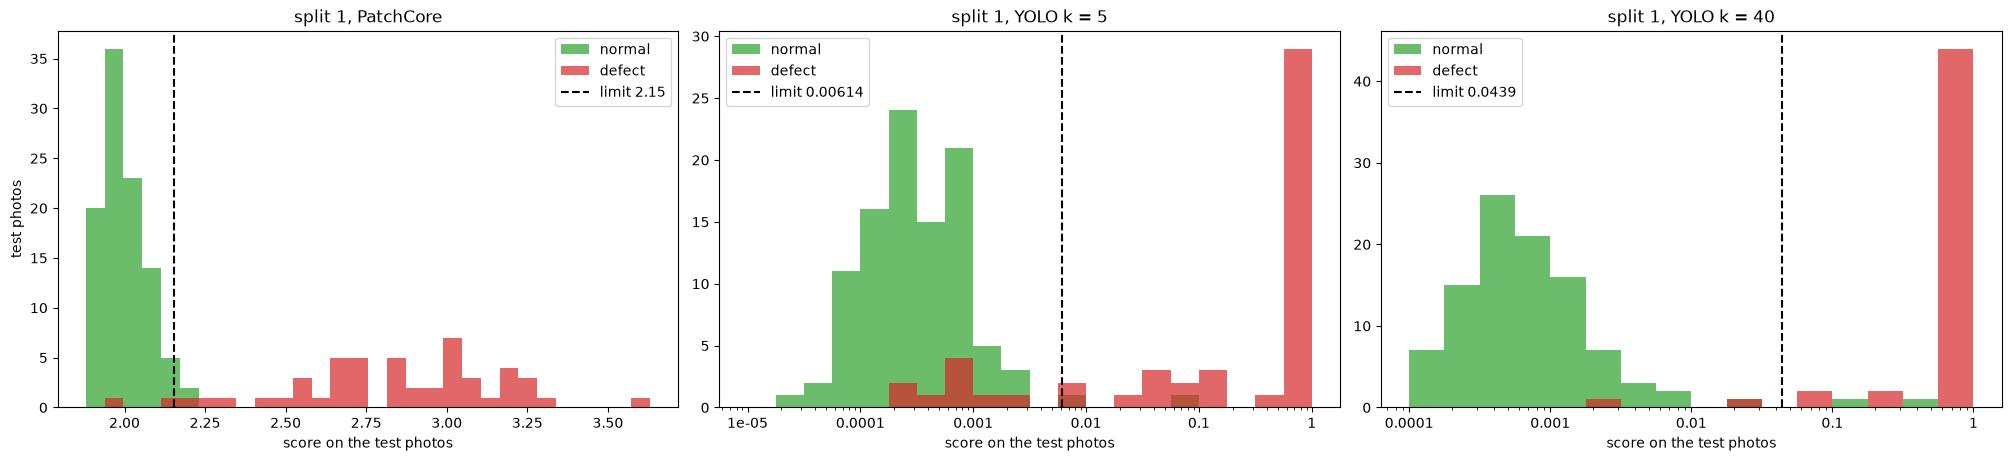

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5), layout="constrained")
for ax, model in zip(axes, ["PatchCore", f"YOLO k = {K_VALUES[0]}", f"YOLO k = {K_VALUES[-1]}"]):
    photos = decisions[(decisions["split"] == EXAMPLE_SPLIT) & (decisions["model"] == model)]
    limit = photos["limit"].iloc[0]
    if model == "PatchCore":
        bins = np.linspace(photos["score"].min(), photos["score"].max(), 31)
    else:
        lowest_power = int(np.floor(np.log10(photos.loc[photos["score"] > 0, "score"].min())))
        bins = np.logspace(lowest_power, 0, 4 * -lowest_power + 1)
        ax.set_xscale("log")
        ticks = 10.0 ** np.arange(lowest_power, 1)
        ax.set_xticks(ticks, [f"{tick:g}" for tick in ticks])
    ax.hist(photos.loc[~photos["is_defect"], "score"], bins=bins, color="tab:green", alpha=0.7, label="normal")
    ax.hist(photos.loc[photos["is_defect"], "score"], bins=bins, color="tab:red", alpha=0.7, label="defect")
    ax.axvline(limit, color="black", linestyle="--", label=f"limit {limit:.3g}")
    ax.set_title(f"split {EXAMPLE_SPLIT}, {model}")
    ax.set_xlabel("score on the test photos")
    ax.legend()
    print(f"{model}: limit {limit:.3g} | defect photos caught {photos.loc[photos['is_defect'], 'rejected'].sum()} "
          f"of {photos['is_defect'].sum()} | normal photos rejected {photos.loc[~photos['is_defect'], 'rejected'].sum()} "
          f"of {(~photos['is_defect']).sum()}")
axes[0].set_ylabel("test photos")
plt.show()

> **What we see** (split 1; a dark bar means green and red in the same place):
>
> - **PatchCore** (limit 2.15): the good photos lie around the tick 2.00, most defect photos between the ticks 2.50 and 3.50, far to the right. One red bar lies left of the limit (49 of 50 caught), and a few green bars lie just right of it (4 of 100 good photos rejected). Near the limit, the two colours are close together.
> - **YOLO k = 5** (limit 0.00614): most defect photos get a score near 1, but several red bars lie among the green ones: these defect photos look like good gum to this model (41 of 50 caught).
> - **YOLO k = 40** (limit 0.0439): almost all defect photos are near 1, far away from most good photos, which stay below the tick 0.01. 2 red bars lie left of the limit (48 of 50 caught) and 2 green bars right of it (2 of 100 good photos rejected).

### The Main Result: All 3 Splits Together

> `overview`: for every model, the sums over the 3 splits (defect photos, caught, normal photos, false rejects) and the means of the 3 splits (catch rate, false-reject rate, AUROC). Every split has 50 defect test photos, so one photo is 2 percentage points of the catch rate of a split.
>
> The figure shows the catch rate, the false-reject rate and the AUROC against k, with one legend for all three panels below them. The grey dotted line in the middle panel is the 5% that the limit allows on the validation photos.

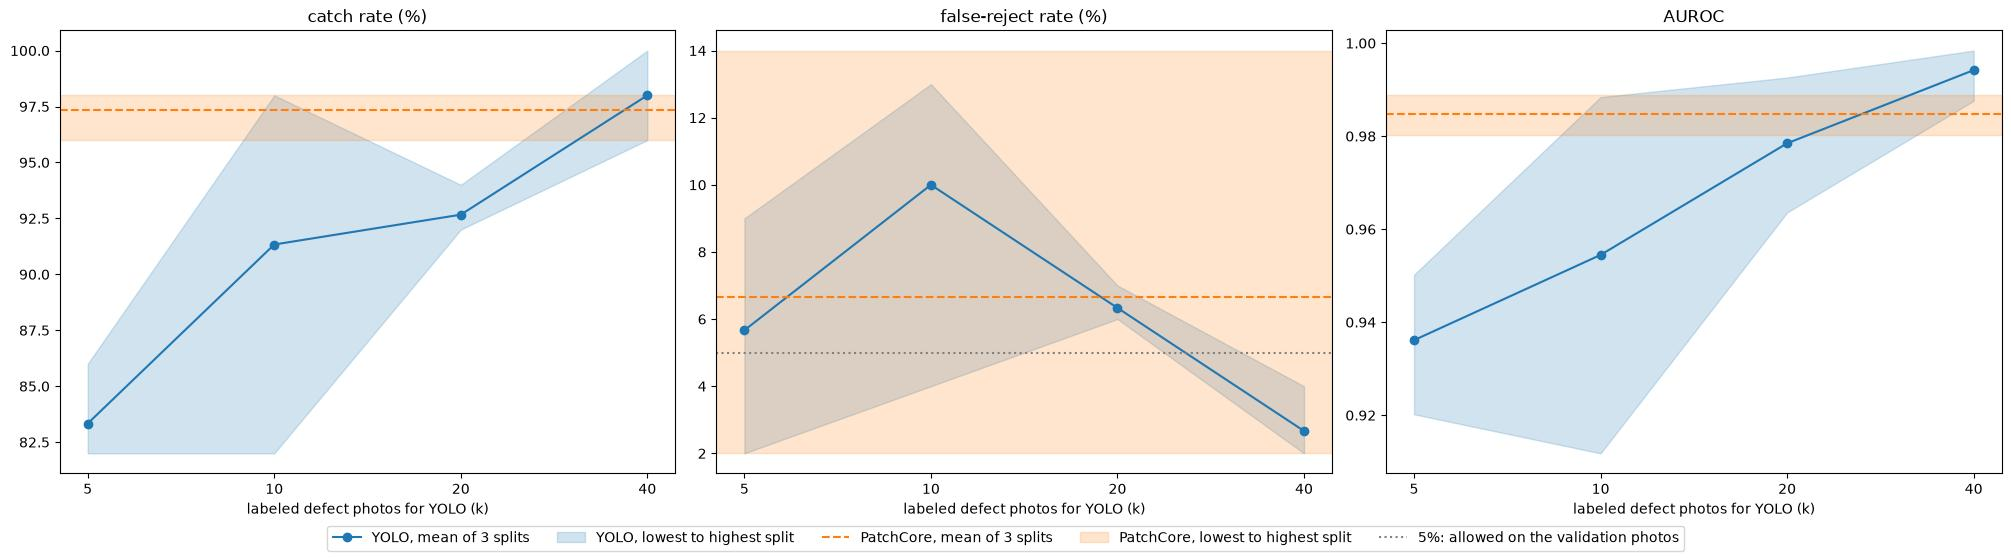

,defect photos,caught,catch rate (%),normal photos,false rejects,false-reject rate (%),AUROC
model,,,,,,,
PatchCore,150,146,97.333,300,20,6.667,0.985
YOLO k = 5,150,125,83.333,300,17,5.667,0.936
YOLO k = 10,150,137,91.333,300,30,10.000,0.954
YOLO k = 20,150,139,92.667,300,19,6.333,0.978
YOLO k = 40,150,147,98.000,300,8,2.667,0.994


In [12]:
overview = results.groupby("model").agg(**{
    "defect photos": ("defect photos", "sum"), "caught": ("caught", "sum"),
    "catch rate (%)": ("catch rate (%)", "mean"),
    "normal photos": ("normal photos", "sum"), "false rejects": ("false rejects", "sum"),
    "false-reject rate (%)": ("false-reject rate (%)", "mean"),
    "AUROC": ("AUROC", "mean")}).loc[MODELS]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), layout="constrained")
for ax, column in zip(axes, ["catch rate (%)", "false-reject rate (%)", "AUROC"]):
    plot_against_k(ax, results, column)
axes[1].axhline(100 * MAX_FALSE_REJECT, color="grey", linestyle=":", label=f"{100 * MAX_FALSE_REJECT:g}%: allowed on the validation photos")
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=5)
plt.show()
overview.round(3)

> **What we see:**
>
> - **PatchCore**, with no labeled defect photo at all: 146 of 150 defect test photos caught (97.3%), 20 of 300 good photos rejected (6.7%), AUROC 0.985.
> - **YOLO** gets better with more labeled photos: 125, 137, 139 and 147 of 150 caught (83.3%, 91.3%, 92.7% and 98.0%). Its AUROC rises from 0.936 to 0.994.
> - **At k = 40**, YOLO catches about as many defects as PatchCore (147 vs 146), rejects fewer good photos (8 vs 20 of 300) and has a higher AUROC (0.994 vs 0.985).
> - The splits differ most at k = 10: the blue band of the catch rate reaches from 82% to 98%. With few labeled photos, the result depends a lot on which photos YOLO learned from.
> - In the middle panel, PatchCore's orange band reaches up to 14% because of split 2. On average, YOLO with k = 10 rejects the most good gum (10.0%).

## Step 3: Does YOLO Catch Up? Photo by Photo

### Caught by Whom

> Both models looked at the same test photos, so they can be compared photo by photo. For every split and k, each of the 50 defect test photos falls into one of four groups:
>
> - `both`: caught by PatchCore and by YOLO,
> - `only PatchCore` or `only YOLO`: caught by one model, missed by the other,
> - `neither`: missed by both.
>
> `YOLO minus PatchCore` is `only YOLO` minus `only PatchCore`: the difference in caught photos. Photos caught by both or by neither do not change it.

In [13]:
pair_rows = []
for s in SPLITS:
    split_defects = decisions[(decisions["split"] == s) & decisions["is_defect"]]
    patchcore_caught = split_defects[split_defects["model"] == "PatchCore"].set_index("image")["rejected"]
    for k in K_VALUES:
        yolo_caught = split_defects[split_defects["model"] == f"YOLO k = {k}"].set_index("image")["rejected"]
        yolo_caught = yolo_caught.loc[patchcore_caught.index]
        pair_rows.append({"k": k, "split": s,
                          "both": int((patchcore_caught & yolo_caught).sum()),
                          "only PatchCore": int((patchcore_caught & ~yolo_caught).sum()),
                          "only YOLO": int((~patchcore_caught & yolo_caught).sum()),
                          "neither": int((~patchcore_caught & ~yolo_caught).sum())})
pairs = pd.DataFrame(pair_rows)
pairs["YOLO minus PatchCore"] = pairs["only YOLO"] - pairs["only PatchCore"]
pairs

,k,split,both,only PatchCore,only YOLO,neither,YOLO minus PatchCore
0,5,1,41,8,0,1,-8
1,10,1,41,8,0,1,-8
2,20,1,45,4,1,0,-3
3,40,1,47,2,1,0,-1
4,5,2,43,6,0,1,-6
5,10,2,46,3,1,0,-2
6,20,2,46,3,1,0,-2
7,40,2,48,1,1,0,0
8,5,3,40,8,1,1,-7
9,10,3,47,1,2,0,1


### The Verdict per k

> The rule from the README: a model **clearly catches more** at this k only if it catches more defect photos in all 3 splits (`verdict()`). Otherwise the result depends on which photos happen to be in a split, and there is **no clear winner**.
>
> The false rejects of both models (sums over the 3 splits) stand next to the verdict, because a model can also catch more defects by rejecting more good gum.

In [14]:
false_rejects = results.set_index(["model", "split"])["false rejects"]
verdict_rows = []
for k in K_VALUES:
    differences = pairs.loc[pairs["k"] == k, "YOLO minus PatchCore"]
    verdict_rows.append({"k": k,
                         "YOLO minus PatchCore per split": " / ".join(f"{d:+d}" for d in differences),
                         "YOLO minus PatchCore, all splits": int(differences.sum()),
                         "verdict": verdict(differences),
                         "false rejects PatchCore": int(false_rejects["PatchCore"].sum()),
                         "false rejects YOLO": int(false_rejects[f"YOLO k = {k}"].sum())})
verdicts = pd.DataFrame(verdict_rows)
verdicts

,k,YOLO minus PatchCore per split,"YOLO minus PatchCore, all splits",verdict,false rejects PatchCore,false rejects YOLO
0,5,-8 / -6 / -7,-21,PatchCore clearly catches more,20,17
1,10,-8 / -2 / +1,-9,no clear winner,20,30
2,20,-3 / -2 / -2,-7,PatchCore clearly catches more,20,19
3,40,-1 / +0 / +2,1,no clear winner,20,8


> **What we see:**
>
> - **k = 5:** PatchCore catches 8, 6 and 8 defect photos that YOLO misses, and YOLO catches only 1 photo that PatchCore misses (split 3). PatchCore clearly catches more: 21 photos more over the 3 splits.
> - **k = 10:** YOLO is behind in splits 1 and 2 (-8 and -2) but 1 photo ahead in split 3, so the rule says no clear winner. In split 3, YOLO also rejects 13 good photos, PatchCore only 2 (Step 2). Over the 3 splits, YOLO is still 9 photos behind.
> - **k = 20:** behind in all 3 splits (-3, -2, -2): PatchCore clearly catches more.
> - **k = 40:** -1, +0 and +2: no clear winner. Over the 3 splits YOLO catches 1 photo more, and it rejects 8 good photos instead of 20.
> - At k = 40, `neither` is 0 in every split: every defect test photo is caught by at least one of the two models.
>
> **Answer to the main question:** with 5, 10 or 20 labeled defect photos, YOLO catches fewer defects than PatchCore, which needs no labeled photo at all. Only with 40 labeled defect photos, the largest amount in this project, does YOLO catch up.

## Step 4: Which Defect Types Are Missed

### Catch Rate per Defect Type

> Every defect photo has one or more defect types (README). For every type: the share of its test photos that each model catches, over the 3 splits together.
>
> - `str.split(",")` turns `"corner missing,small cracks"` into a list of two types, and `explode()` gives the photo one row per type. So a photo with two types counts for both types.
> - A photo that is a test photo in two splits also counts twice, once per split.
> - `photos`: how many test photos (over the 3 splits) have this type. The fewer photos, the more one photo changes the percentage.

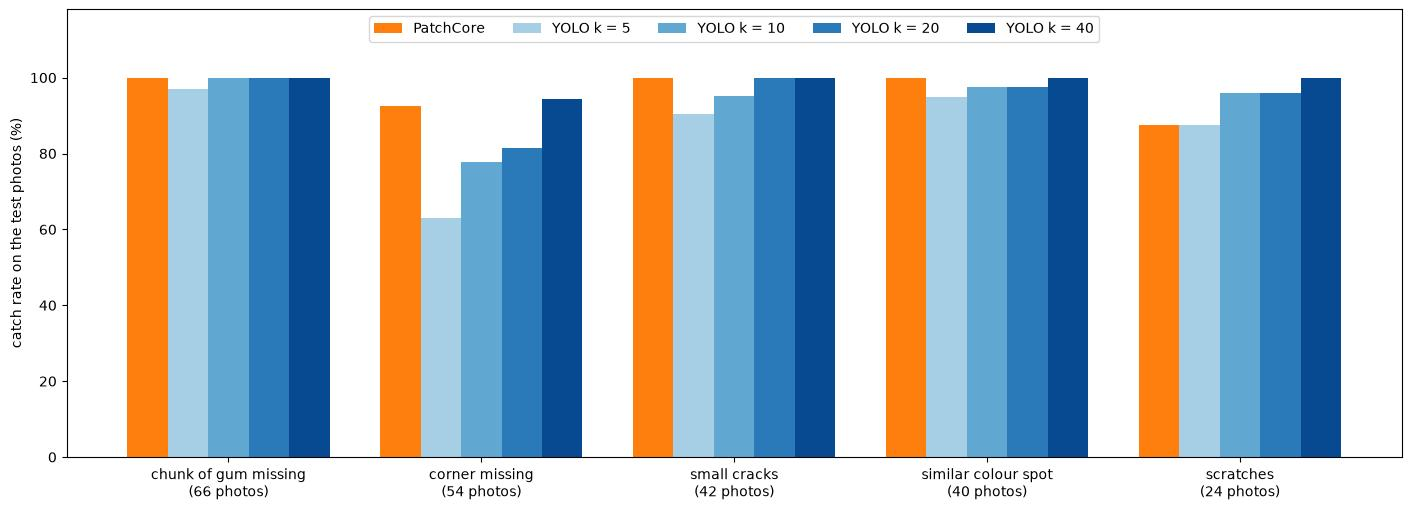

model,photos,PatchCore,YOLO k = 5,YOLO k = 10,YOLO k = 20,YOLO k = 40
defect_type,,,,,,
chunk of gum missing,66,100.0,97.0,100.0,100.0,100.0
corner missing,54,92.6,63.0,77.8,81.5,94.4
small cracks,42,100.0,90.5,95.2,100.0,100.0
similar colour spot,40,100.0,95.0,97.5,97.5,100.0
scratches,24,87.5,87.5,95.8,95.8,100.0


In [15]:
by_type = decisions[decisions["is_defect"]].copy()
by_type["defect_type"] = by_type["defect_types"].str.split(",")
by_type = by_type.explode("defect_type")
type_table = 100 * by_type.pivot_table(index="defect_type", columns="model", values="rejected", aggfunc="mean")
type_table = type_table.loc[DEFECT_TYPES, MODELS]
type_table.insert(0, "photos", by_type[by_type["model"] == "PatchCore"].groupby("defect_type").size().loc[DEFECT_TYPES])

fig, ax = plt.subplots(figsize=(14, 5), layout="constrained")
positions = np.arange(len(DEFECT_TYPES))
width = 0.16
colors = ["tab:orange"] + list(plt.cm.Blues(np.linspace(0.35, 0.9, len(K_VALUES))))
for i, (model, color) in enumerate(zip(MODELS, colors)):
    ax.bar(positions + (i - (len(MODELS) - 1) / 2) * width, type_table[model], width=width, color=color, label=model)
ax.set_xticks(positions, [f"{defect_type}\n({count} photos)" for defect_type, count in zip(DEFECT_TYPES, type_table["photos"])])
ax.set_ylabel("catch rate on the test photos (%)")
ax.set_ylim(0, 118)
ax.legend(ncol=len(MODELS), loc="upper center")
plt.show()
type_table.round(1)

> **What we see:**
>
> - *chunk of gum missing*, *small cracks* and *similar colour spot*: PatchCore catches all of them (100%), and so does YOLO with k = 40.
> - **corner missing** is the hardest type for both models: PatchCore 92.6%, YOLO 63.0% with 5 labeled photos and 94.4% with 40. The labels help YOLO most with this type.
> - PatchCore misses only 4 defect test photos in total (146 of 150), and 92.6% of the 54 corner photos means 4 missed corner photos. So every photo PatchCore misses has a missing corner. 3 of them also have scratches (87.5% of 24 means 3 missed), which is why PatchCore's catch rate on scratches is 87.5%.
> - YOLO with k = 40 misses 3 photos in total (147 of 150), all with a missing corner too (94.4% of 54 means 3 missed).
> - A possible reason, to check in the next notebook: where a corner is missing, the photo shows mat instead of gum, and PatchCore's memory bank holds many mat patches (notebook 4.1). So a missing corner can look normal to PatchCore.

## Step 5: Save the Limits and Results

### Preview Before Saving

> What will be saved in `results/evaluation/`:
>
> - `score_limits.csv`: the table `limits` (Step 1), for the demo and the next notebooks.
> - `test_decisions.csv`: the table `decisions` (Step 2): every test photo with its score, limit and decision, for every split and model.
> - `test_results.csv`: the table `results` (Step 2).
>
> Below: the size of every table and the first rows of `decisions`.

In [16]:
for name, table in [("score_limits.csv", limits), ("test_decisions.csv", decisions), ("test_results.csv", results)]:
    print(f"{name}: {table.shape[0]} rows x {table.shape[1]} columns")
decisions.head()

score_limits.csv: 15 rows x 6 columns
test_decisions.csv: 2250 rows x 11 columns
test_results.csv: 15 rows x 10 columns


,split,model,k,image,crop_image,part,is_defect,defect_types,score,limit,rejected
0,1,PatchCore,0,chewinggum/Data/Images/Anomaly/000.JPG,images/Anomaly/000.png,test,True,"chunk of gum missing,scratches,small cracks",3.253945,2.153118,True
1,1,PatchCore,0,chewinggum/Data/Images/Anomaly/001.JPG,images/Anomaly/001.png,test,True,"corner missing,small cracks",2.834428,2.153118,True
2,1,PatchCore,0,chewinggum/Data/Images/Anomaly/003.JPG,images/Anomaly/003.png,test,True,"corner missing,small cracks",3.045915,2.153118,True
3,1,PatchCore,0,chewinggum/Data/Images/Anomaly/006.JPG,images/Anomaly/006.png,test,True,"chunk of gum missing,small cracks",3.207382,2.153118,True
4,1,PatchCore,0,chewinggum/Data/Images/Anomaly/007.JPG,images/Anomaly/007.png,test,True,"chunk of gum missing,corner missing,small cracks",3.061606,2.153118,True


### Save

> `os.makedirs(..., exist_ok=True)` makes the folder if it does not exist yet. Running this cell again replaces the files. Then every saved file is listed with its size.

In [17]:
os.makedirs(EVALUATION_DIR, exist_ok=True)
limits.to_csv(os.path.join(EVALUATION_DIR, "score_limits.csv"), index=False)
decisions.to_csv(os.path.join(EVALUATION_DIR, "test_decisions.csv"), index=False)
results.to_csv(os.path.join(EVALUATION_DIR, "test_results.csv"), index=False)

for name in sorted(os.listdir(EVALUATION_DIR)):
    path = os.path.join(EVALUATION_DIR, name)
    print(f"{os.path.relpath(path, ROOT_DIR)}: {os.path.getsize(path) / 1024:,.0f} KB")

results\evaluation\score_limits.csv: 1 KB
results\evaluation\test_decisions.csv: 310 KB
results\evaluation\test_results.csv: 1 KB


### Read the Files Back

> A quick check that the saved files hold what we meant to save: the same number of rows, the same limits, the same decisions and the same results as the tables in memory.

In [18]:
saved_limits = pd.read_csv(os.path.join(EVALUATION_DIR, "score_limits.csv"))
saved_decisions = pd.read_csv(os.path.join(EVALUATION_DIR, "test_decisions.csv"))
saved_results = pd.read_csv(os.path.join(EVALUATION_DIR, "test_results.csv"))
print("score_limits.csv: same limits", len(saved_limits) == len(limits) and np.allclose(saved_limits["limit"], limits["limit"]))
print("test_decisions.csv: same decisions", len(saved_decisions) == len(decisions)
      and np.array_equal(saved_decisions["rejected"], decisions["rejected"]))
print("test_results.csv: same results", len(saved_results) == len(results)
      and np.allclose(saved_results[["catch rate (%)", "false-reject rate (%)", "AUROC"]], results[["catch rate (%)", "false-reject rate (%)", "AUROC"]]))

score_limits.csv: same limits True
test_decisions.csv: same decisions True
test_results.csv: same results True


> **What we see:** all three checks are True: the files hold the same limits, decisions and results as the tables in memory.

## Summary

> **What this notebook did**
>
> - Set one PASS/REJECT limit for every model of every split, from its 50 normal validation photos only: at most 5% of them, so 2 photos, get REJECT.
> - Used each limit once on the 150 test photos of its split: catch rate, false-reject rate and AUROC.
> - Compared PatchCore and YOLO photo by photo, gave a verdict for every k, and compared the catch rate per defect type.
> - Saved the limits, the decisions and the results (`results/evaluation/`), and read them back to check them.
>
> **What we found (test photos, 3 splits)**
>
> - PatchCore, without any labeled defect photo: 97.3% of the defect test photos caught, 6.7% of the good ones rejected, AUROC 0.985.
> - YOLO: 83.3%, 91.3%, 92.7% and 98.0% caught with 5, 10, 20 and 40 labeled defect photos, and 5.7%, 10.0%, 6.3% and 2.7% of the good photos rejected.
> - PatchCore clearly catches more at k = 5 and k = 20. At k = 10 the rule finds no clear winner, but YOLO is still 9 photos behind. At k = 40, YOLO has caught up (147 vs 146 caught) and rejects fewer good photos (8 vs 20 of 300).
> - Both models miss mostly photos with a missing corner.
> - With only 50 good validation photos to set the limit, the false-reject rate on the test photos moved away from 5% in some splits (up to 14%).
>
> **Data leakage:** the limits come from validation photos only. The test photos were used once, with rules that were written down before (README), and nothing was changed after seeing the results.
>
> **Next:** the mistakes of both models (where the heatmap and the boxes point on missed defects and false rejects), and the time per photo.